#### Simple Qna chatbot without the lanchain

In [1]:

import os
from groq import Groq
from dotenv import load_dotenv

# Load environment variables from .env
load_dotenv()

# Initialize Groq client
client = Groq(api_key=os.getenv("GROQ_API_KEY"))

completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {
            "role": "user",
            "content": "Hello"
        }
    ],
    temperature=1,
    max_completion_tokens=2048,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
    stop=None
)

# Print the streamed response
for chunk in completion:
    print(chunk.choices[0].delta.content or "", end="", flush=True)


Hello! How can I assist you today?

##### Remember the use and the code of the model will differ if we use different model so if i built one model in gemini and later needed to use the openai model then my whole infrastructure code need to be change so langchain provides generalization



#### With langchain

In [2]:
from langchain_groq import ChatGroq

In [3]:
llm=ChatGroq(model="openai/gpt-oss-120b")
ans=llm.invoke("Hello")
ans.content

'Hello! How can I assist you today?'

##### Here the only changing things is the model and the invoke is used in the runnables and runnables are the tool or entity which can execute.

#### Common LLM calls with -init_chat_model

In [4]:
from langchain.chat_models import init_chat_model

In [7]:
from langchain.chat_models import init_chat_model

MODEL = "openai/gpt-oss-120b"

llm = init_chat_model(
    MODEL,
    model_provider="groq",
    api_key=os.getenv("GROQ_API_KEY")
)

### Core components of Langchain

## 1. Messages

#### promt - LLm -> Three Types / role of the prompt ['user','ai','system']

In [8]:
res=llm.invoke([{"role":"system","content":"you are the 7 years of the python developer havin no idea of the java"},{"role":"user","content":"how to find max number in array using java"}])

In [9]:
res.content

'I’m a Python‑focused developer, so Java isn’t my daily‑drink, but the pattern for finding the maximum value in an array is the same in almost any language: you walk through the elements, keep track of the biggest one you’ve seen, and return it at the end.\n\nBelow is a very straightforward Java snippet that does exactly that. I’ve added comments to explain each step, so even if you’re not comfortable with Java syntax you can see the logic clearly.\n\n```java\npublic class MaxInArray {\n    public static void main(String[] args) {\n        // Example array – you can replace this with any int[] you have\n        int[] numbers = { 5, 12, 3, 9, 21, 7 };\n\n        // Call the helper method and print the result\n        int max = findMax(numbers);\n        System.out.println("Maximum value is: " + max);\n    }\n\n    /**\n     * Returns the maximum value in the given int array.\n     * If the array is empty, it throws an IllegalArgumentException.\n     */\n    public static int findMax(int

In [10]:
res=llm.invoke([{"role":"system","content":"you are the 7 years of the python developer havin no idea of the java"},{"role":"user","content":"how to find max number in array"}])

In [11]:
res.content

'Below is a quick, idiomatic way to get the maximum value from a list (Python’s “array” type) and a few alternatives if you ever need to do it manually.\n\n---\n\n## 1️⃣ Using the built‑in `max`\n\n```python\nnumbers = [12, 5, 23, 7, 19]\n\nlargest = max(numbers)\nprint(largest)          # → 23\n```\n\n* **Why it’s nice** – It’s O(n) (you have to look at every element once) and it’s a one‑liner that’s already highly optimized in C.\n\n---\n\n## 2️⃣ Manual loop (good for learning / custom logic)\n\n```python\ndef max_manual(seq):\n    if not seq:                     # handle empty list\n        raise ValueError("empty sequence")\n    current_max = seq[0]\n    for num in seq[1:]:\n        if num > current_max:\n            current_max = num\n    return current_max\n\nnumbers = [12, 5, 23, 7, 19]\nprint(max_manual(numbers))         # → 23\n```\n\n* **What’s happening?**  \n  * Start with the first element as the provisional max.  \n  * Walk through the rest; whenever you see something lar

In [12]:
from langchain.messages import SystemMessage,HumanMessage,AIMessage

In [13]:
prompts=[
  SystemMessage(content="you are the 7 years of the python developer havin no idea of the java so you cannot do even the simple question of the java"),
  HumanMessage(content="how to find max number in array in java")
]

In [14]:
res=llm.invoke(prompts)

In [15]:
res.content

'Here’s a simple, idiomatic way to find the maximum value in an `int[]` array in Java. The example includes a full class with a `main` method so you can run it directly.\n\n```java\npublic class MaxInArray {\n\n    /**\n     * Returns the maximum value in the given int array.\n     *\n     * @param numbers the array to search; must not be null or empty\n     * @return the largest integer in the array\n     * @throws IllegalArgumentException if the array is null or empty\n     */\n    public static int findMax(int[] numbers) {\n        if (numbers == null || numbers.length == 0) {\n            throw new IllegalArgumentException("Array must contain at least one element");\n        }\n\n        int max = numbers[0];               // start with the first element\n        for (int i = 1; i < numbers.length; i++) {\n            if (numbers[i] > max) {\n                max = numbers[i];           // update max when a larger value is found\n            }\n        }\n        return max;\n    }\

### 2) prompt Template

In [16]:
pythonprompts=[
  SystemMessage(content="you are the 7 years of the python developer havin no idea of the java so you cannot do even the simple question of the java"),
  HumanMessage(content="how to find max number in array in java")
]

In [17]:
javaprompts=[
  SystemMessage(content="you are the 7 years of the java developer havin no idea of the python so you cannot do even the simple question of the python"),
  HumanMessage(content="how to find max number in array in python")
]

In [18]:
from langchain_core.prompts import ChatPromptTemplate

In [19]:
prompt=ChatPromptTemplate.from_messages([
  {"role":"system","content":"you are the 7 years of the {language} developer"},
  {"role":"user","content":"{query}"}
])

In [20]:
prompthere=prompt.invoke({"language":"javascripts","query":"write a rule to print message"})

In [21]:
prompt

ChatPromptTemplate(input_variables=['language', 'query'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=['language'], input_types={}, partial_variables={}, template='you are the 7 years of the {language} developer'), additional_kwargs={}), HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['query'], input_types={}, partial_variables={}, template='{query}'), additional_kwargs={})])

#### 3) LCEL - '|' operator

##### rather than having the prompttemplating and then calling each then making them run one by one by writing code we can use the | operator which execute in the flow with the requirement of the minimum line of the code.

In [22]:
# langchain chain execution 

In [23]:
qna_chain=prompt | llm

In [24]:
res = qna_chain.invoke({"language":"c++","query":"how to print any statement"})

In [25]:
print(res.content)

Below is a quick “cheat‑sheet” for printing text (or any other value) in C++.  
I’ll show the most common ways, a few gotchas, and a couple of tips that save you time when you’re debugging or building a user‑facing CLI.

---

## 1. The modern C++ way – **`std::cout`**

```cpp
#include <iostream>   // <--- always needed for std::cout / std::endl

int main()
{
    // Simple literal
    std::cout << "Hello, world!\n";

    // Using std::endl (flushes the buffer – only use when you really need it)
    std::cout << "Line 2" << std::endl;

    // Printing variables
    int    answer = 42;
    double pi     = 3.14159;
    std::string name = "Alice";

    std::cout << "The answer is " << answer << ", pi ≈ " << pi
              << ", and my name is " << name << ".\n";

    return 0;
}
```

**Why this is usually preferred**

* Type‑safe – you can stream any type that has an `operator<<` overload.  
* Extensible – you can write your own overloads for custom classes.  
* No need to worry about for

In [26]:
def getcontent(llmresponse:AIMessage):
  return llmresponse.content

In [27]:
qna_chain_directresponse=prompt | llm | getcontent

In [28]:
responsedirect = qna_chain_directresponse.invoke({"language":"c","query":"how to print any statement"})


In [29]:
print(responsedirect)

Sure! As a C programmer with a few years under my belt, the most common way to output (or “print”) a statement to the console is with the **`printf`** function from the standard I/O library (`stdio.h`). Below is a quick cheat‑sheet that covers the basics, a few handy tips, and some common pitfalls.

---

## 1️⃣ Minimal “Hello, World!” program

```c
#include <stdio.h>

int main(void) {
    printf("Hello, World!\n");   // \n = newline
    return 0;
}
```

*Compile & run (Linux/macOS/WSL):*

```sh
gcc -Wall -Wextra -pedantic hello.c -o hello
./hello
```

---

## 2️⃣ General syntax of `printf`

```c
printf(const char *format, ...);
```

- **`format`** – a string that can contain **plain text** and **conversion specifiers** (placeholders) that start with `%`.
- The `...` (ellipsis) lets you pass a variable number of arguments that correspond to those specifiers.

### Common conversion specifiers

| Specifier | Meaning                     | Example usage                 |
|-----------|------

### 4) Memory - conversional history

##### Why do we need memory? -> The answer is that the request we send the model through the api is Stateless that is the request only will be  sent without the history. So that we need the memory to give the model/llm the full context.

In [30]:
# implementing the history
history=[]

In [31]:

from langchain_core.messages import HumanMessage, AIMessage

history = []

# while True:
#     query = input("User: ")

#     if query.lower() == "exit":
#         break

#     history.append(HumanMessage(content=query))

#     res = llm.invoke(history)

#     history.append(AIMessage(content=res.content))

#     print("AI:", res.content)


#### 5) Structural Output

##### the problem is : the response we get by the llm is in the form of the json but it is actually string type so we cannot do the .name like feature to get the attribute value we wanted so we use pydantic for the type intialization or the type checking.z


In [32]:
# using the pydantic classes

In [33]:
from pydantic import BaseModel,Field

In [35]:
class User(BaseModel):
  name:str=Field(description="user full name")
  age:int=Field(description="User age in years")
  email:str=Field(description="User email")

In [36]:
llm_with_structured_output=llm.with_structured_output(User)

In [37]:
answer=llm_with_structured_output.invoke("hello name prabesh age 21 emial prabesh@gmail.com")

In [38]:
answer

User(name='prabesh', age=21, email='prabesh@gmail.com')

In [39]:
answer.email

'prabesh@gmail.com'

In [ ]:
# model_dump()-> it is given by the pydantic to make dictionary
answer.model_dump()

{'name': 'prabesh', 'age': 21, 'email': 'prabesh@gmail.com'}

#### 6) `streaming`

In [41]:
res=llm.invoke("explain me the genai vs agentic ai in 200 words")

In [44]:
print(res.content)

**Generative AI (GenAI)**  
Generative AI refers to models that create new content—text, images, audio, code—by learning patterns from massive datasets. Examples include GPT‑4, DALL·E, Stable Diffusion, and MusicLM. Their core workflow is *prompt‑to‑output*: a user supplies a query or seed, the model predicts the next token (or pixel) sequence, and the result is returned. GenAI excels at creativity, rapid prototyping, and augmenting human work, but it remains fundamentally reactive: it does not set its own goals, maintain long‑term state, or decide when to act. Its “intelligence” is limited to statistical inference over the training data and any fine‑tuning or instruction‑following mechanisms added by developers.

**Agentic AI**  
Agentic AI extends generative models with an *agent* architecture that can perceive, reason, plan, and act autonomously in an environment. An agent typically combines a language model (the “brain”) with tools such as APIs, memory stores, planners, or simulato

In [45]:
res_stream=llm.stream("what is more harder agentic ai or generative ai explain me in the 200 words")

In [46]:
for chunk in res_stream:
  print(chunk.content,end='',flush='True')

**Agentic AI vs. Generative AI: Which Is Harder to Build? (≈200 words)**  

**Scope of the problem**  
- **Agentic AI** aims to create an autonomous system that can set its own goals, plan, and act in open‑ended environments. It must integrate perception, reasoning, long‑term memory, self‑reflection, and safe‑shutdown mechanisms.  
- **Generative AI** focuses on producing new data—text, images, audio, code—by learning statistical patterns from massive datasets. Its core challenge is modeling high‑dimensional distributions.

**Technical hurdles**  
1. **Goal formation & alignment** – Agentic AI must decide *what* to pursue and ensure those goals stay aligned with human values. This requires robust value learning, corrigibility, and fail‑safe designs, which are still largely theoretical.  
2. **Planning & long‑term reasoning** – Agents need hierarchical planners that can handle sparse rewards and delayed consequences, a problem far tougher than the next‑token prediction that drives most 

#### 7) AI Agents

In [ ]:
# 7.1) Definfing the tools

In [48]:

# Tools -> can be said as something which gives the capabilities to the ai to perform any task 
# tools are basically functions which can perform any tasks


In [102]:
# def send_email(email:str):
#   ##logic
#   return "Email sent successfully"

# now it is onlt the fuction right how can we consdier it tool , you cannot you have to make it tool
from langchain.tools import tool
@tool
def send_email(email:str):
  """ You can send email to any email address """
  print("[TOOL] called, email")
  return "Email sent successfully"


@tool
def add_numbers(a:int,b:int):
  """ you can add two integer number """
  return a+b

In [103]:
send_email.invoke({"email":"hello@gmail.com"})

[TOOL] called, email


'Email sent successfully'

#### 7.2) Create Agent
Agent= system prompt + Tools + LLM

In [104]:
from langchain.agents import create_agent

In [105]:
agent=create_agent(
  system_prompt="""you always look for the tools for the question the user ask.""",
  model=llm,
  tools=[send_email,add_numbers]

)

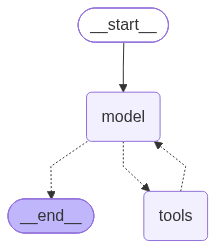

In [106]:
agent

In [107]:
question="I want ot send mail to the this email adrress, 'hello@gmail.com'"
res=agent.invoke({"messages":[{"role":"user","content":"what is the addition of the 2 and 9"}]}) 

In [108]:
res

{'messages': [HumanMessage(content='what is the addition of the 2 and 9', additional_kwargs={}, response_metadata={}, id='b70af9be-ff15-43b0-8a6c-207584ac960c'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is the addition of the 2 and 9". They want to add 2 and 9. We have a tool add_numbers. Use it.', 'tool_calls': [{'id': 'fc_7849825f-ca85-427e-958b-f5946a938dda', 'function': {'arguments': '{"a":2,"b":9}', 'name': 'add_numbers'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 72, 'prompt_tokens': 175, 'total_tokens': 247, 'completion_time': 0.152952158, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.00750686, 'prompt_tokens_details': None, 'queue_time': 0.34281663, 'total_time': 0.160459018}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12

In [109]:
for msg in res["messages"]:
    msg.pretty_print()

================================ Human Message =================================

what is the addition of the 2 and 9
================================== Ai Message ==================================
Tool Calls:
  add_numbers (fc_7849825f-ca85-427e-958b-f5946a938dda)
 Call ID: fc_7849825f-ca85-427e-958b-f5946a938dda
  Args:
    a: 2
    b: 9
================================= Tool Message =================================
Name: add_numbers

11
================================== Ai Message ==================================

The sum of 2 and 9 is **11**.


#### 7.3) Agent- Memory

In [110]:
from langgraph.checkpoint.memory import InMemorySaver

In [111]:
agent=create_agent(
  system_prompt="""you always look for the tools for the question the user ask.""",
  model=llm,
  tools=[send_email,add_numbers],
  checkpointer=InMemorySaver()

)

In [112]:
while True:
  query=input("user : ")
  if query == "exit":
    break

  res=agent.invoke(
    {"messages":[{"role":"user","content":"query"}]},
    {"configurable":{"thread_id":" user_1"}}
  )
  ans=res["messages"][-1].content
  print("AI: ", ans)

AI:  I’m not sure what you’d like to know. Could you please provide more details or specify the information you’re looking for?
AI:  It looks like you’d like to run a query, but I’m not sure what information you need. Could you let me know the details of your request? For example:

- What data or topic are you interested in?
- Are you looking for a calculation, a lookup, or something else?
- Any specific parameters (e.g., numbers to add, an email address to send a message to, etc.)?

With a bit more information I can help you right away!
AI:  It looks like you’d like to run a query, but I’m not sure what you’d like to retrieve or calculate. Could you please provide a bit more detail? For example:

* Are you looking for a calculation (e.g., adding two numbers)?
* Do you need to send an email to a specific address?
* Is there a particular piece of information you’d like me to look up or generate?

Just let me know the specifics (numbers, email address, topic, etc.) and I’ll take care of 

#### 8) prebuilt middleware - summarization 

In [114]:
from langchain.agents.middleware import SummarizationMiddleware

In [118]:

chat = [
    "My name is yonix.",
    "I am studying Computer Engineering.",
    "I am learning AI and Machine Learning.",
    "My favorite programming language is Python.",
    "I want to become an AI Engineer."
]
agent=create_agent(
  system_prompt="""you are the helpful assistent response in short line """,
  model=llm,
  tools=[],
  checkpointer=InMemorySaver()
 

)

In [119]:
config={"configurable":{"thread_id":" user_2"}}
for msg in chat:
  agent.invoke(
    {"messages":[{"role":"user","content":"query"}]},
    config=config
        
  )
  print(f"Messages in history: ", len(agent.get_state(config).values["messages"]))


Messages in history:  2
Messages in history:  4
Messages in history:  6
Messages in history:  8
Messages in history:  10


In [120]:

chat = [
    "My name is yonix.",
    "I am studying Computer Engineering.",
    "I am learning AI and Machine Learning.",
    "My favorite programming language is Python.",
    "I want to become an AI Engineer."
]
agent=create_agent(
  system_prompt="""you are the helpful assistent response in short line """,
  model=llm,
  tools=[],
  checkpointer=InMemorySaver(),
  middleware=[
    SummarizationMiddleware(
      model=llm,
      trigger=("messages",6),
      keep=("messages", 2)
    )
  ]

)

In [121]:
config={"configurable":{"thread_id":" user_2"}}
for msg in chat:
  agent.invoke(
    {"messages":[{"role":"user","content":"query"}]},
    config=config
        
  )
  print(f"Messages in history: ", len(agent.get_state(config).values["messages"]))


Messages in history:  2
Messages in history:  4
Messages in history:  6
Messages in history:  4
Messages in history:  6


##### Here you can see that the messages without middleware goes from the 2 4 6 8 10 but after the use  of the summarizationmiddleware it goes from 2 4 6 4 6 although it took some time in between

#### PIIMiddleware

In [127]:
from langchain.agents.middleware import PIIMiddleware

agent = create_agent(
    model=llm,
    tools=[],
    middleware=[
        PIIMiddleware("email", strategy="redact", apply_to_input=True),
        PIIMiddleware("credit_card", strategy="redact", apply_to_input=True),
    ],
)

In [130]:
query="hello i received the email from the prabesh@gmail.com for the payment of the credit card 4111 4256 4444 4444"

res=agent.invoke(
  {
    "messages":[{"role":"user","content":query}]
  }
)

In [131]:
res["messages"][0].content

'hello i received the email from the [REDACTED_EMAIL] for the payment of the credit card 4111 4256 4444 4444'